# ROI_processing

In [2]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData

import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns

import hotspot

/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [2]:
# Technology 1: Xenium
sdata = sd.read_zarr("/media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k/data_processed_factor.zarr")#"/media/sergio/Meninges/troutpy/rois/xenium_mscolon_5k/data_processed_filtered.zarr")
saving_path='/media/sergio/Meninges/troutpy/figures'

# Contribution score

We compute the contribution score

In [39]:
troutpy.tl.compute_contribution_score(sdata)

<Axes: title={'center': 'uRNA contribution score'}, xlabel='UMAP1', ylabel='UMAP2'>

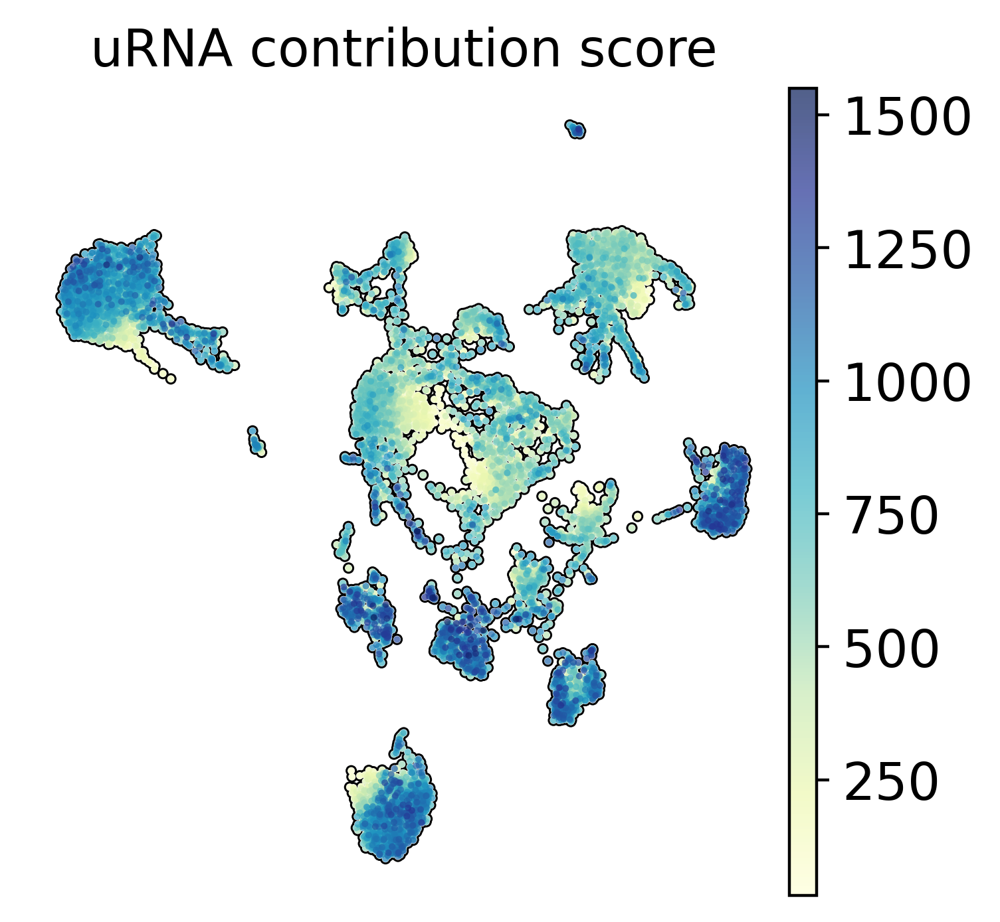

In [83]:
import matplotlib
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

sc.set_figure_params(scanpy=True, dpi=200, dpi_save=200, frameon=True, vector_friendly=True, fontsize=14, figsize=None, color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')
sc.pl.umap(sdata['table'],color='urna_contribution_score',cmap='YlGnBu',add_outline=True,frameon=False,title='uRNA contribution score',show=False,vmax='p99.99')

In [46]:
sdata['table'].uns['cell_type_colors'] = [
    "#0FCCAC",   # Aqua Teal – bright and fresh, great for highlighting
    "#ED2073",   # Vivid Magenta Pink – strong contrast, eye-catching
    "#ebb434", 
    "#BFCE00",   # Chartreuse Green – light, acidic green, good for uncommon categories
    "#DF5AFF",   # Electric Purple – vibrant, stands out, ideal for rare cell types
    "#FC911D",   # Vivid Orange – warm and bold, useful for attention-grabbing
    "#E891B4",   # Pastel Rose – soft and gentle, good for subtle categories
    "#eb3d34",   # Mint Cream – pale green, useful for background or low-contrast layers
    "#37BEE2",   # Bright Sky Blue – vibrant and energetic, visually accessible
    "#790DB7",   # Royal Purple – deep and rich, contrasts well with yellows and greens
    "#ff69f7",   # Lime Green – bold but not neon, works well for active states
    "#43FBFF",   # Neon Cyan – very bright, best with dark backgrounds
    "#F7C894",   # Peach – soft and neutral, ideal for subtle cell states
    "#BCBCBC",   # Medium Gray – neutral, useful as a baseline or control color
    "#5cc460",   # Charcoal – strong neutral, works well for text or background
    "#9CFFFC",
    "#123755",   # Deep Navy Blue – dark and cool, good background or strong category
    "#FFFF7B",   # Soft Lemon Yellow – light and readable on dark backgrounds
]

coldict=dict(zip(np.unique(sdata['table'].obs['cell_type']),sdata['table'].uns['cell_type_colors']))

cols=[coldict[o] for o in order_selected]

In [3]:
troutpy.tl.compute_contribution_score(sdata)

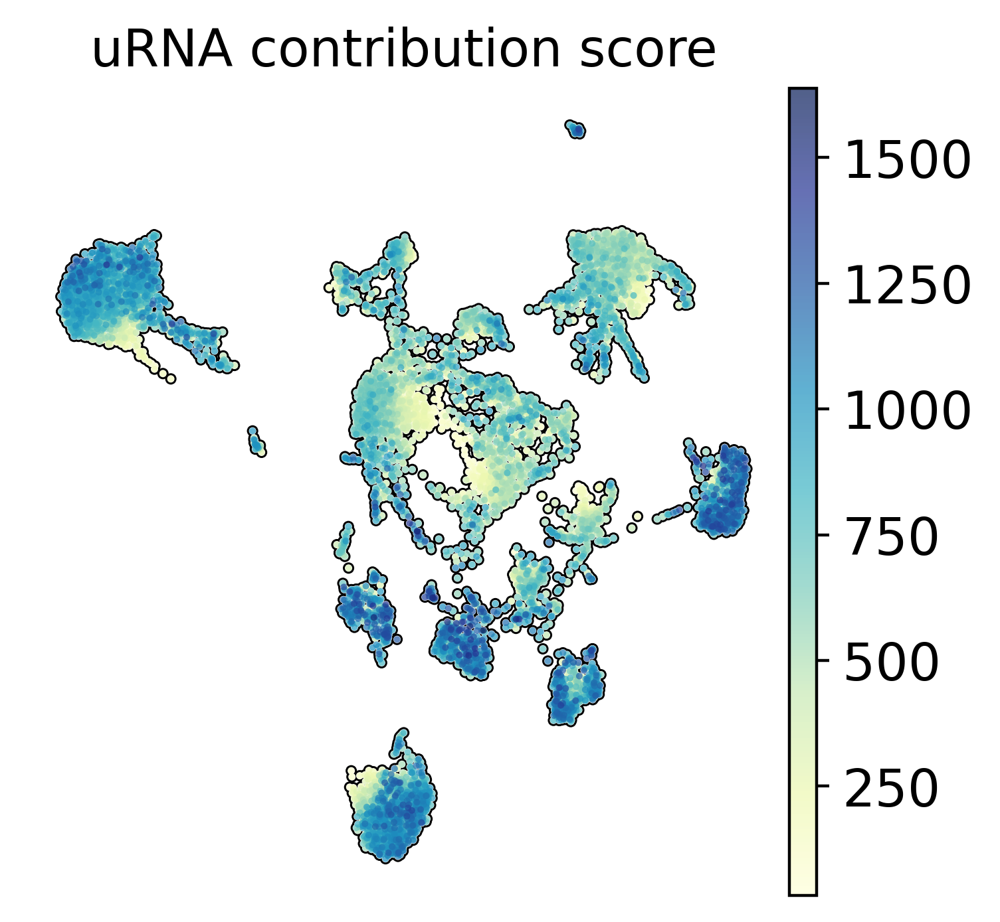

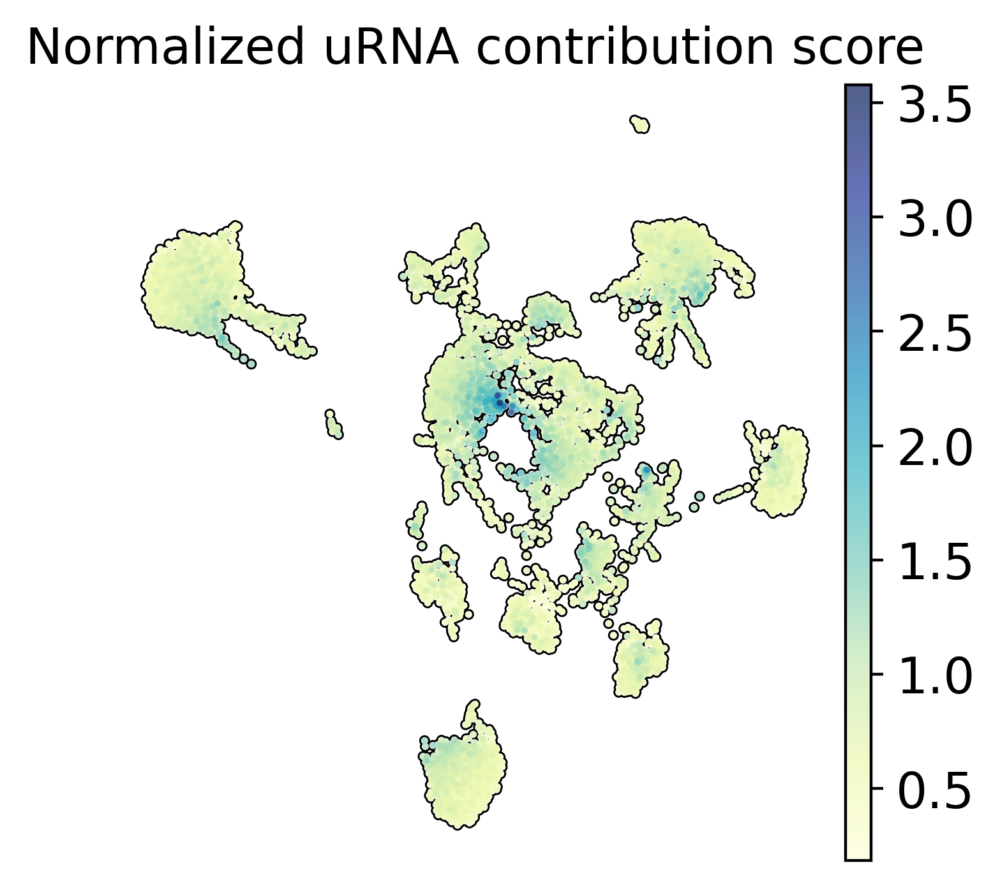

In [88]:
import matplotlib
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

sc.set_figure_params(scanpy=True, dpi=200, dpi_save=200, frameon=True, vector_friendly=True, fontsize=14, figsize=None, color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')
sc.pl.umap(sdata['table'],color='urna_contribution_score',cmap='YlGnBu',add_outline=True,frameon=False,title='uRNA contribution score',show=False)
plt.savefig(os.path.join(saving_path,'cells_umap_contribution_score.pdf'))

sc.set_figure_params(scanpy=True, dpi=200, dpi_save=200, frameon=True, vector_friendly=True, fontsize=14, figsize=None, color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')
sc.pl.umap(sdata['table'],color='normalized_urna_contribution_score',cmap='YlGnBu',add_outline=True,frameon=False,title='Normalized uRNA contribution score',show=False)
plt.savefig(os.path.join(saving_path,'cells_umap_normalized_contribution_score.pdf'))

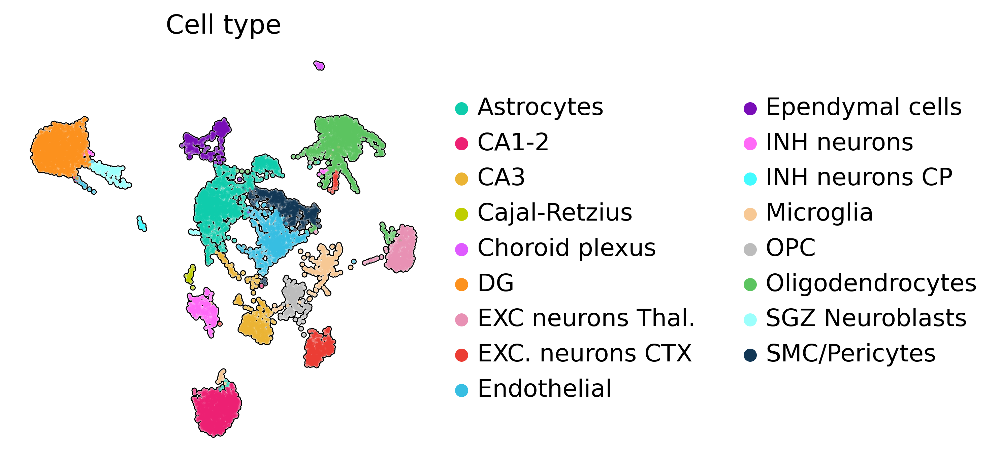

In [94]:
sc.set_figure_params(scanpy=True, dpi=200, dpi_save=200, frameon=True, vector_friendly=True, fontsize=14, figsize=None, color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')
import matplotlib
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
sc.pl.umap(sdata['table'],color='cell_type',add_outline=True,frameon=False,title='Cell type',show=False)
plt.savefig(os.path.join(saving_path,'cells_umap_cell_type.pdf'))

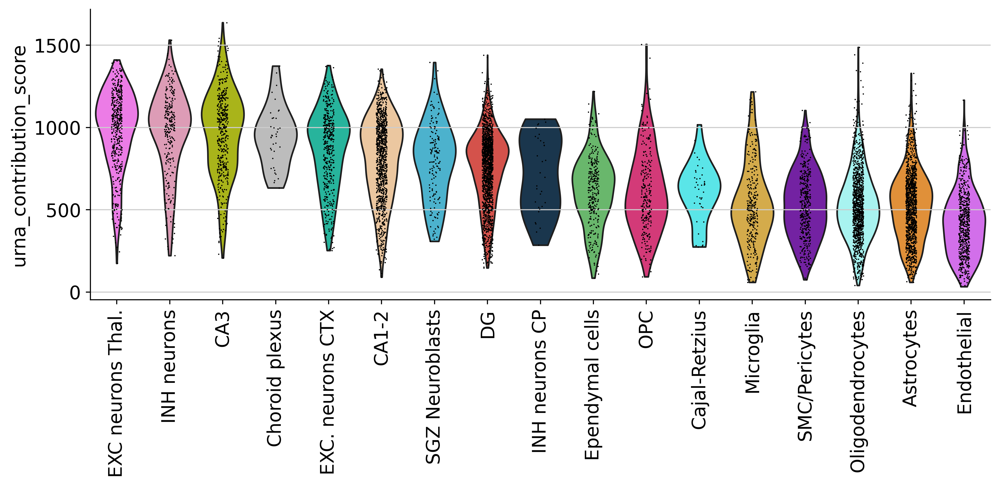

In [89]:
import matplotlib
import matplotlib.pyplot as plt
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
sc.set_figure_params(scanpy=True, dpi=200, dpi_save=200, frameon=True, vector_friendly=True, fontsize=14, figsize=(10,4), color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')

# Select order
order_selected=sdata['table'].obs.loc[:,['urna_contribution_score','cell_type']].groupby('cell_type').mean().sort_values(by='urna_contribution_score',ascending=False).index

coldict=dict(zip(np.unique(sdata['table'].obs['cell_type']),sdata['table'].uns['cell_type_colors']))
cols=[coldict[o] for o in order_selected]

# Your violin plot
sc.pl.violin(
    sdata['table'],
    'urna_contribution_score',
    groupby='cell_type',
    rotation=90,
    palette=cols,
    show=False,
    order=order_selected
)

# Remove outer box (spines)
ax = plt.gca()
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(saving_path,'cells_violin_contribution_score.pdf'))


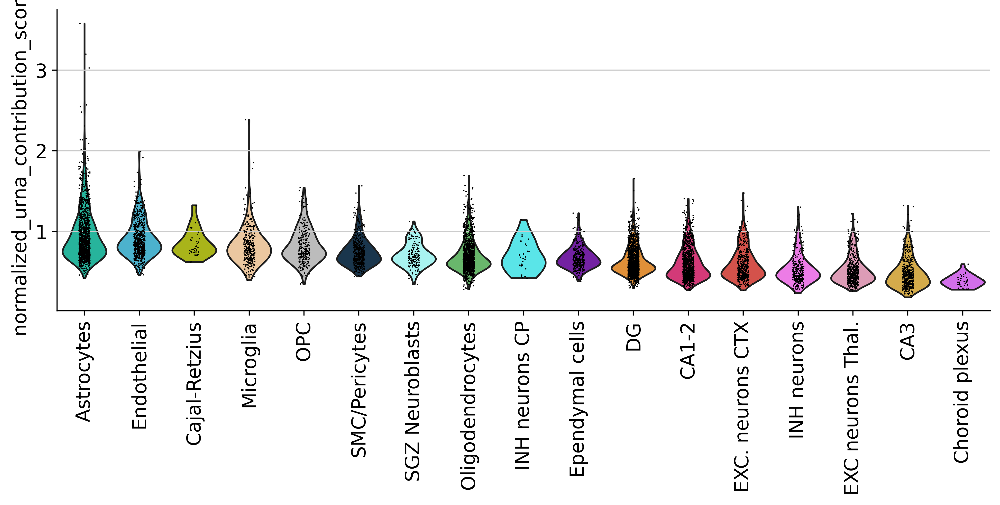

In [95]:
import matplotlib
import matplotlib.pyplot as plt
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
sc.set_figure_params(scanpy=True, dpi=200, dpi_save=200, frameon=True, vector_friendly=True, fontsize=14, figsize=(10,4), color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')

# Select order
order_selected=sdata['table'].obs.loc[:,['normalized_urna_contribution_score','cell_type']].groupby('cell_type').mean().sort_values(by='normalized_urna_contribution_score',ascending=False).index

coldict=dict(zip(np.unique(sdata['table'].obs['cell_type']),sdata['table'].uns['cell_type_colors']))
cols=[coldict[o] for o in order_selected]

# Your violin plot
sc.pl.violin(
    sdata['table'],
    'normalized_urna_contribution_score',
    groupby='cell_type',
    rotation=90,
    palette=cols,
    show=False,
    order=order_selected
)

# Remove outer box (spines)
ax = plt.gca()
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(saving_path,'cells_violin_normalized_contribution_score.pdf'))


In [97]:
contribution_by_celltype=sdata['table'].obs.loc[:,['urna_contribution_score','cell_type']].groupby('cell_type').sum()
ct_freqs=sdata['table'].obs.groupby('cell_type').count()
ct_freqs=ct_freqs.iloc[:,[0]]
ct_freqs.columns=['total_cells']
contribution_by_celltype=pd.concat([contribution_by_celltype,ct_freqs],axis=1)

In [107]:
coldict

['#0FCCAC',
 '#37BEE2',
 '#BFCE00',
 '#F7C894',
 '#BCBCBC',
 '#123755',
 '#9CFFFC',
 '#5cc460',
 '#43FBFF',
 '#790DB7',
 '#FC911D',
 '#ED2073',
 '#eb3d34',
 '#ff69f7',
 '#E891B4',
 '#ebb434',
 '#DF5AFF']

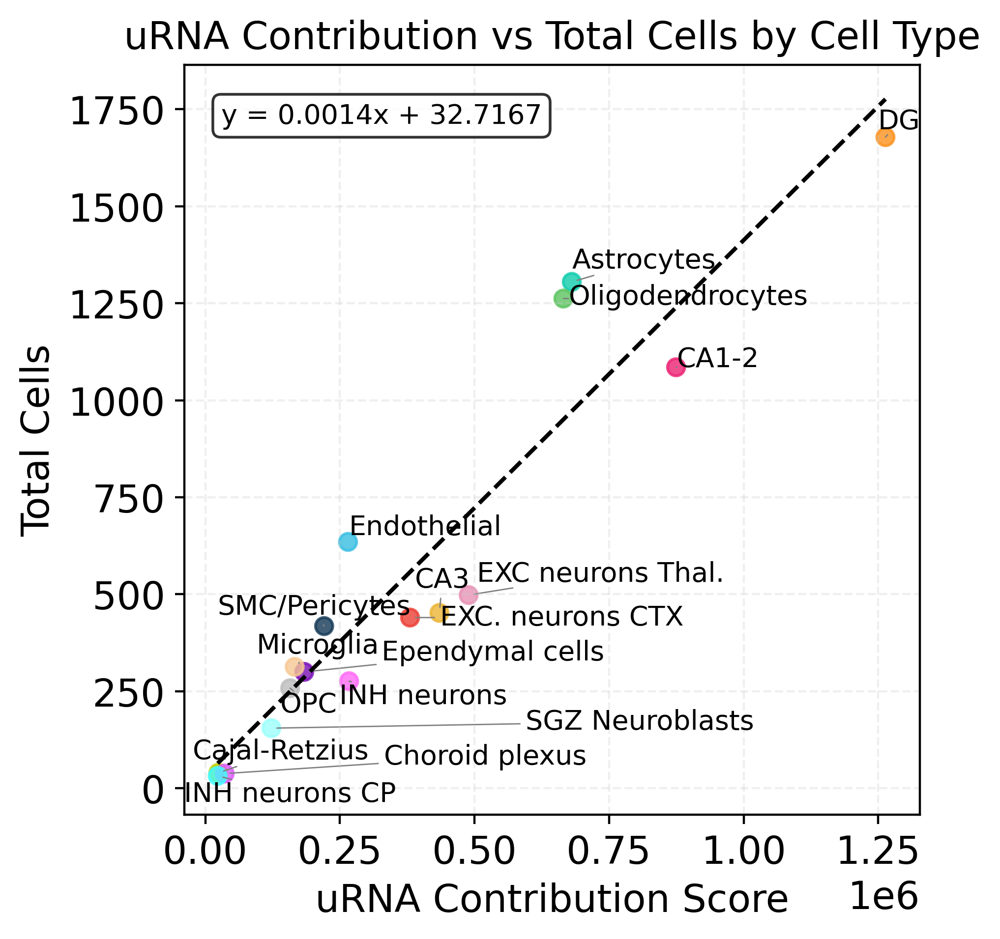

In [123]:
import matplotlib.pyplot as plt
from adjustText import adjust_text
import numpy as np

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

# Data
x = contribution_by_celltype['urna_contribution_score']
y = contribution_by_celltype['total_cells']
colors = contribution_by_celltype.index.map(coldict)

# Scatter plot
plt.figure(figsize=(5, 5))
plt.scatter(x, y, c=colors, s=40, alpha=0.8)

# Add labels with adjustText to avoid overlap
texts = []
for idx, row in contribution_by_celltype.iterrows():
    label = row.name  # Or use row['cell_type'] if preferred
    texts.append(
        plt.text(
            row['urna_contribution_score'],
            row['total_cells'],
            label,
            fontsize=10
        )
    )
adjust_text(texts, arrowprops=dict(arrowstyle='-', color='gray', lw=0.5))

# Fit and plot trend line
coeffs = np.polyfit(x, y, deg=1)
trendline = np.poly1d(coeffs)
x_vals = np.linspace(x.min(), x.max(), 200)
y_vals = trendline(x_vals)
plt.plot(x_vals, y_vals, color='black', linestyle='--', linewidth=1.5, label='Trend')

# Add trendline equation as text
a, b = coeffs
equation = f"y = {a:.4f}x + {b:.4f}"
plt.text(
    0.05, 0.95, equation,
    transform=plt.gca().transAxes,
    fontsize=10,
    verticalalignment='top',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8)
)

# Labels and layout
plt.xlabel('uRNA Contribution Score')
plt.ylabel('Total Cells')
plt.title('uRNA Contribution vs Total Cells by Cell Type')
plt.grid(True, linestyle='--', alpha=0.3)
#plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(saving_path,'scatter_urna_contribution_vs_total_cells.pdf'))
plt.show()


# Now we compute source score

In [68]:
troutpy.tl.compute_source_score(sdata, layer="transcripts", gene_key="gene", lambda_decay=0.1, copy=False, celltype_key="cell_type",n_jobs=4)

Processing genes: 100%|███████████████████████████████████████████████████████████| 4279/4279 [2:22:45<00:00,  2.00s/it]


Now we save the results as a zarr, since computing source score takes a while

In [70]:
sdata.write("/media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k/data_processed_with_scores.zarr",overwrite=True)#"/media/sergio/Meninges/troutpy/rois/xenium_mscolon_5k/data_processed_filtered.zarr")

INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside /media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k/data_processed_with_scores.zarr). 
         Please see the documentation of `is_self_contained()` to understand the implications of working with      
         SpatialData objects that are not self-contained.                                                          
INFO     The Zarr backing store has been changed from                                                              
         /media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k/data_processed_factor.zarr the new file path:       
         /media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k/data_processed_with_scores.zarr                     


## Read the file again

In [6]:
sdata=sd.read_zarr("/media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k/data_processed_with_scores.zarr")
saving_path='/media/sergio/Meninges/troutpy/figures'

# Source score metric- plots

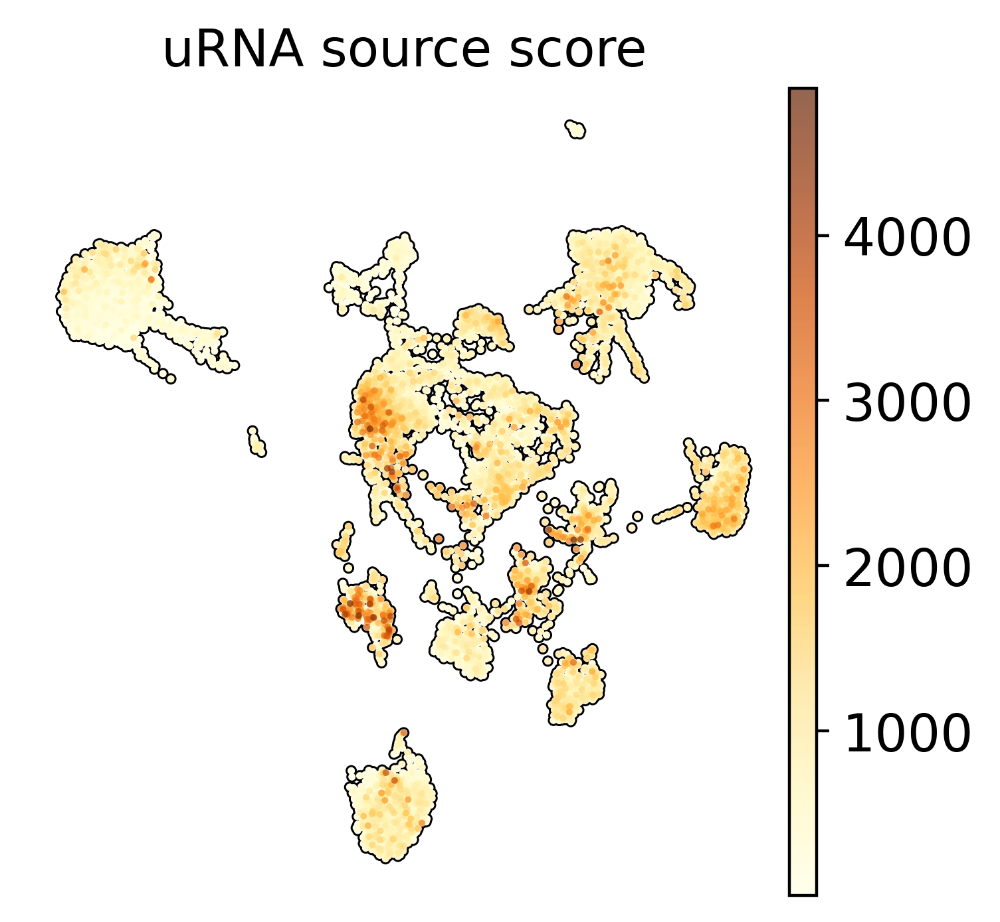

In [124]:
import matplotlib
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

sc.set_figure_params(scanpy=True, dpi=200, dpi_save=200, frameon=True, vector_friendly=True, fontsize=14, figsize=None, color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')
sc.pl.umap(sdata['table'],color='urna_source_score',cmap='YlOrBr',add_outline=True,frameon=False,title='uRNA source score',show=False,vmax='p99.995')
plt.savefig(os.path.join(saving_path,'cells_umap_source_score.pdf'))

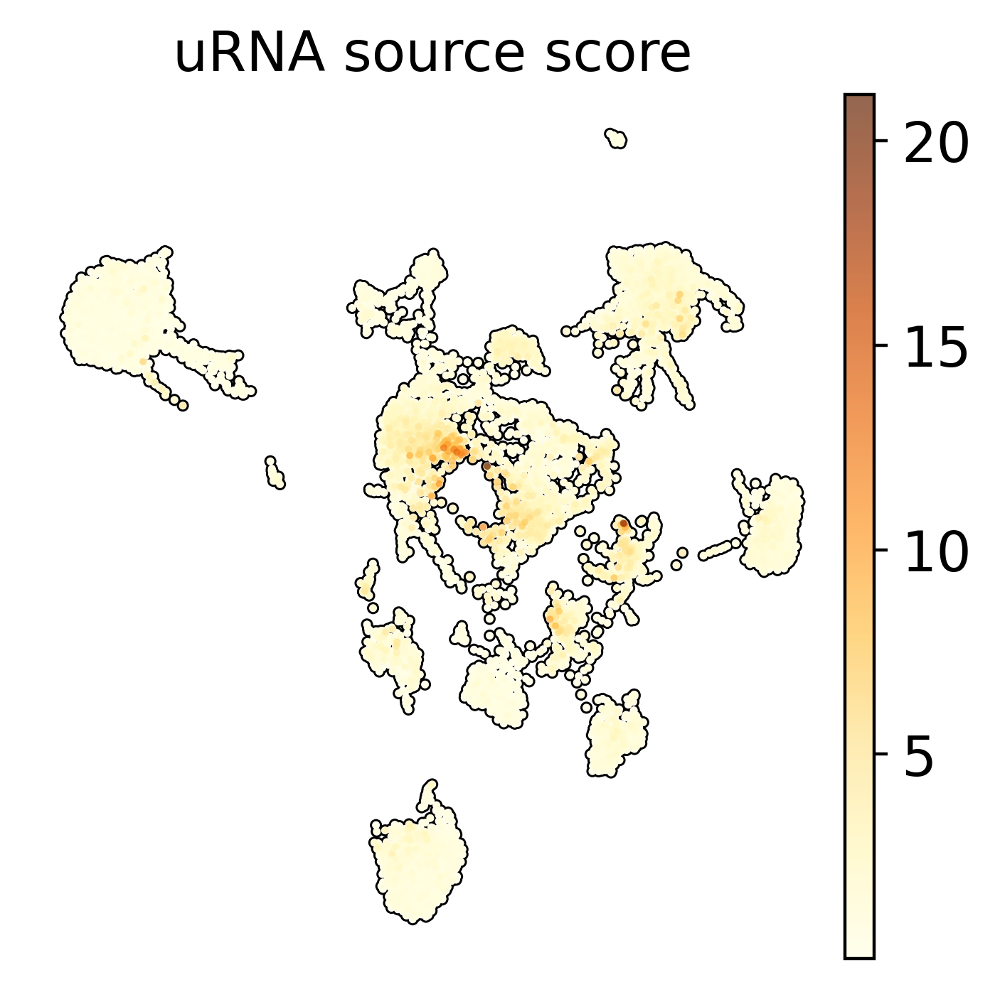

In [125]:
import matplotlib
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

sc.set_figure_params(scanpy=True, dpi=200, dpi_save=200, frameon=True, vector_friendly=True, fontsize=14, figsize=None, color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')
sc.pl.umap(sdata['table'],color='normalized_urna_source_score',cmap='YlOrBr',add_outline=True,frameon=False,title='uRNA source score',show=False,vmax='p99.995')
plt.savefig(os.path.join(saving_path,'cells_umap_source_score_norm.pdf'))

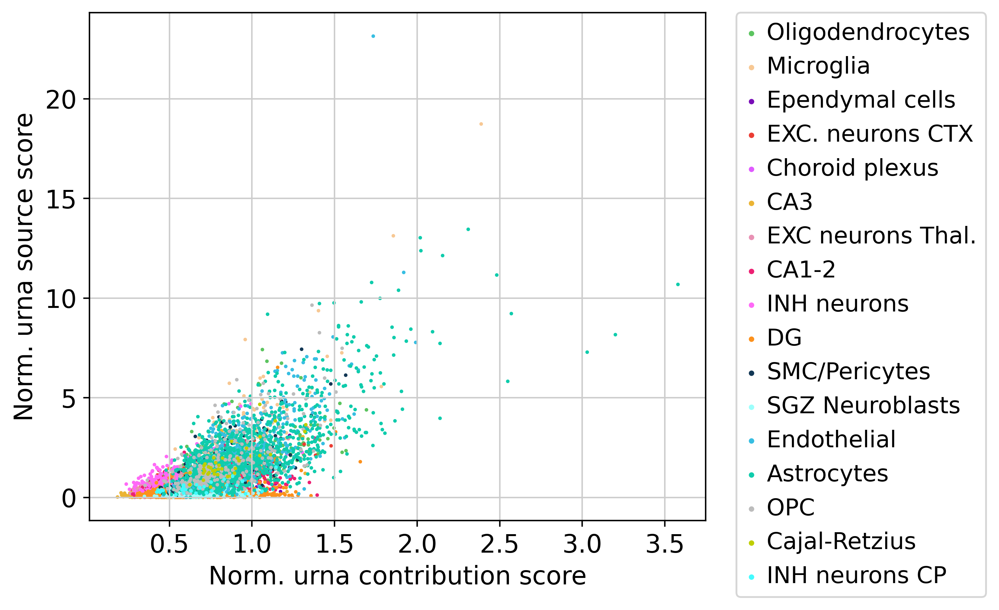

In [133]:
import matplotlib.pyplot as plt
import numpy as np

# Create the color dictionary
coldict = dict(zip(
    np.unique(sdata['table'].obs['cell_type']),
    sdata['table'].uns['cell_type_colors']
))

plt.figure(figsize=(8, 5))

for cell_type in sdata['table'].obs['cell_type'].unique():
    subset = sdata['table'].obs[sdata['table'].obs['cell_type'] == cell_type]
    plt.scatter(
        subset['normalized_urna_contribution_score'],
        subset['normalized_urna_source_score'],
        s=1,
        color=coldict[cell_type],
        label=cell_type,
        alpha=1
    )

plt.xlabel('Norm. urna contribution score')
plt.ylabel('Norm. urna source score')
plt.legend(markerscale=2, bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.tight_layout()
plt.savefig(os.path.join(saving_path,'scatter_norm_urna_contribution_vs_source.pdf'))

plt.show()


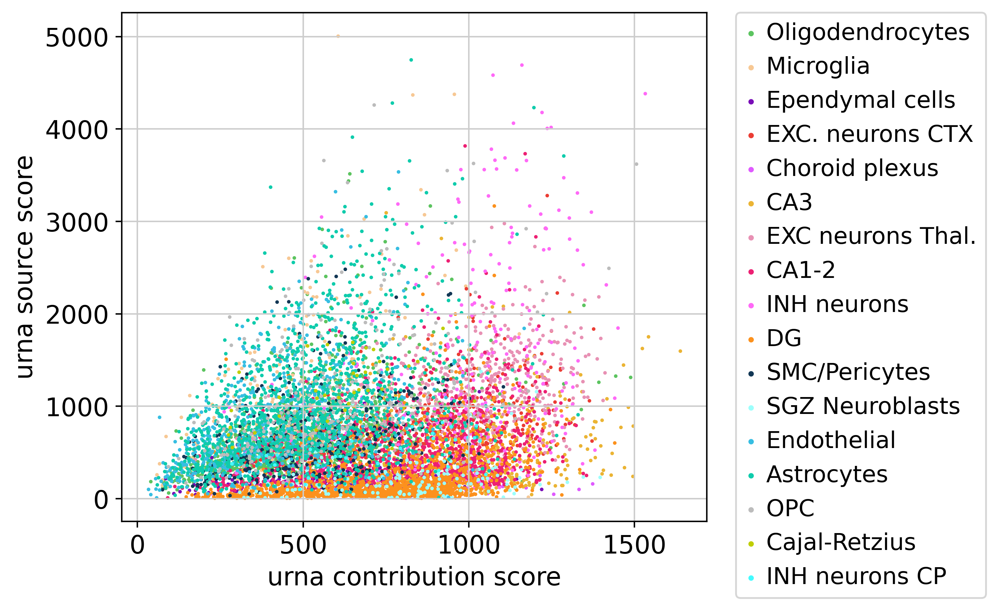

In [134]:
import matplotlib.pyplot as plt
import numpy as np

# Create the color dictionary
coldict = dict(zip(
    np.unique(sdata['table'].obs['cell_type']),
    sdata['table'].uns['cell_type_colors']
))

plt.figure(figsize=(8, 5))

for cell_type in sdata['table'].obs['cell_type'].unique():
    subset = sdata['table'].obs[sdata['table'].obs['cell_type'] == cell_type]
    plt.scatter(
        subset['urna_contribution_score'],
        subset['urna_source_score'],
        s=1,
        color=coldict[cell_type],
        label=cell_type,
        alpha=1
    )

plt.xlabel('urna contribution score')
plt.ylabel('urna source score')
plt.legend(markerscale=2, bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.tight_layout()
plt.savefig(os.path.join(saving_path,'scatter_urna_contribution_vs_source.pdf'))

plt.show()


In [ ]:
sc.pl.spatial?

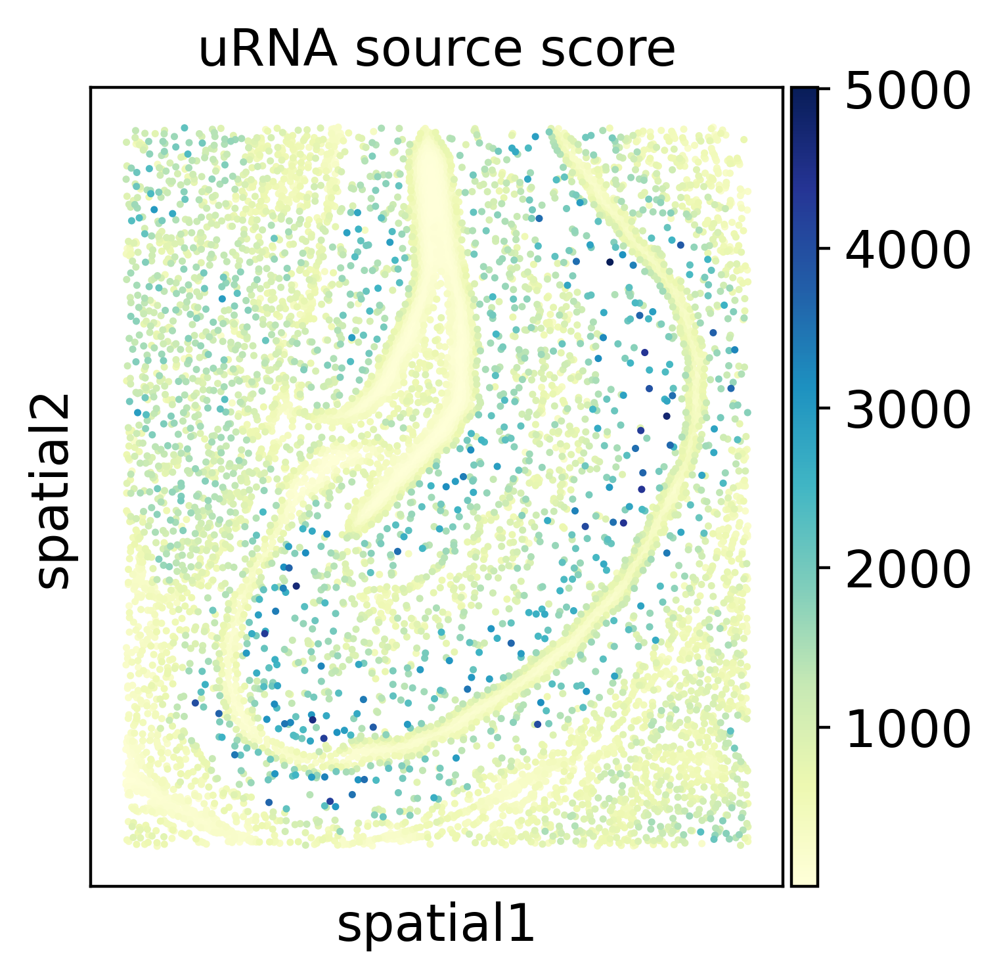

In [12]:
sc.pl.spatial(sdata['table'],color='urna_source_score',cmap='YlGnBu',spot_size=20,title='uRNA source score',save=True)

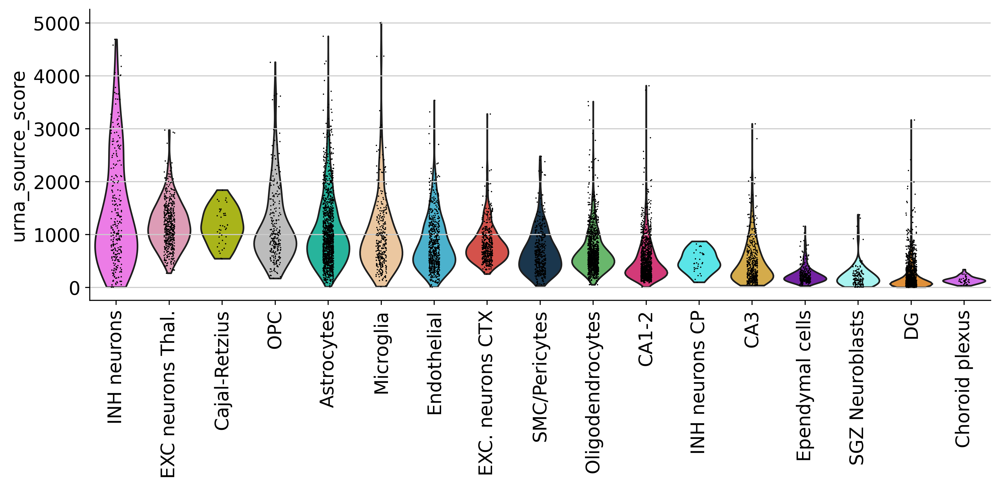

In [127]:
import matplotlib
import matplotlib.pyplot as plt
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
sc.set_figure_params(scanpy=True, dpi=200, dpi_save=200, frameon=True, vector_friendly=True, fontsize=14, figsize=(10,4), color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')

# Select order
order_selected=sdata['table'].obs.loc[:,['urna_source_score','cell_type']].groupby('cell_type').mean().sort_values(by='urna_source_score',ascending=False).index
coldict=dict(zip(np.unique(sdata['table'].obs['cell_type']),sdata['table'].uns['cell_type_colors']))
cols=[coldict[o] for o in order_selected]

# Your violin plot
sc.pl.violin(
    sdata['table'],
    'urna_source_score',
    groupby='cell_type',
    rotation=90,
    palette=cols,
    show=False,
    order=order_selected
)

# Remove outer box (spines)
ax = plt.gca()
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(saving_path,'cells_violin_source_score.pdf'))


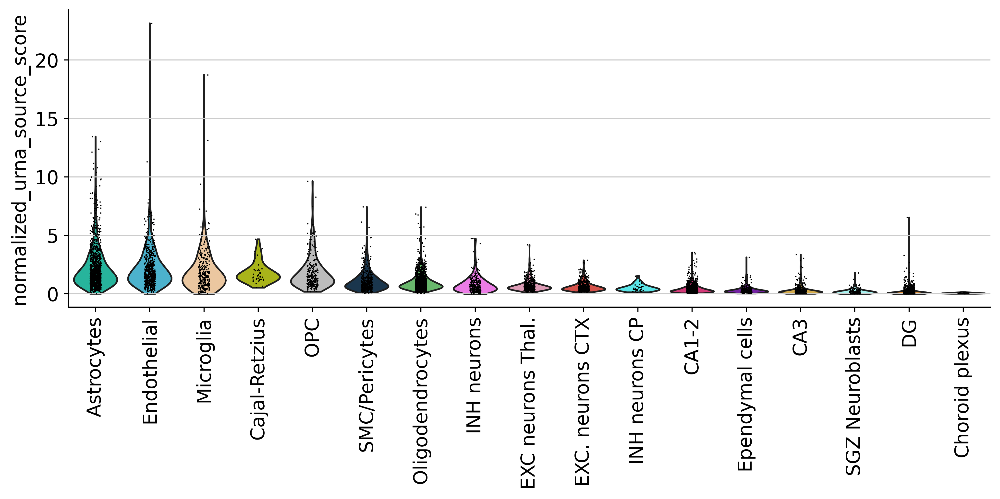

In [128]:
import matplotlib
import matplotlib.pyplot as plt
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
sc.set_figure_params(scanpy=True, dpi=200, dpi_save=200, frameon=True, vector_friendly=True, fontsize=14, figsize=(10,4), color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')

# Select order
order_selected=sdata['table'].obs.loc[:,['normalized_urna_source_score','cell_type']].groupby('cell_type').mean().sort_values(by='normalized_urna_source_score',ascending=False).index
cols=[coldict[o] for o in order_selected]
# Your violin plot
sc.pl.violin(
    sdata['table'],
    'normalized_urna_source_score',
    groupby='cell_type',
    rotation=90,
    palette=cols,
    show=False,
    order=order_selected
)

# Remove outer box (spines)
ax = plt.gca()
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(saving_path,'cells_violin_normalized_source_score.pdf'))


# Identifying genes without a clear source

In [171]:
sdata['source_score'].obs['sum_source_score']=np.sum(sdata['source_score'].X,axis=1)
source_score_by_gene=sdata['source_score'].obs.groupby('gene').mean('sum_source_score')
count_by_gene=sdata['source_score'].obs.groupby('gene').count()
source_score_by_gene['total_counts']=count_by_gene['distance']
combined_urna_metadata=pd.concat([source_score_by_gene,sdata['xrna_metadata'].var],axis=1)
combined_urna_metadata=combined_urna_metadata[combined_urna_metadata['logfoldratio_over_noise']>4]

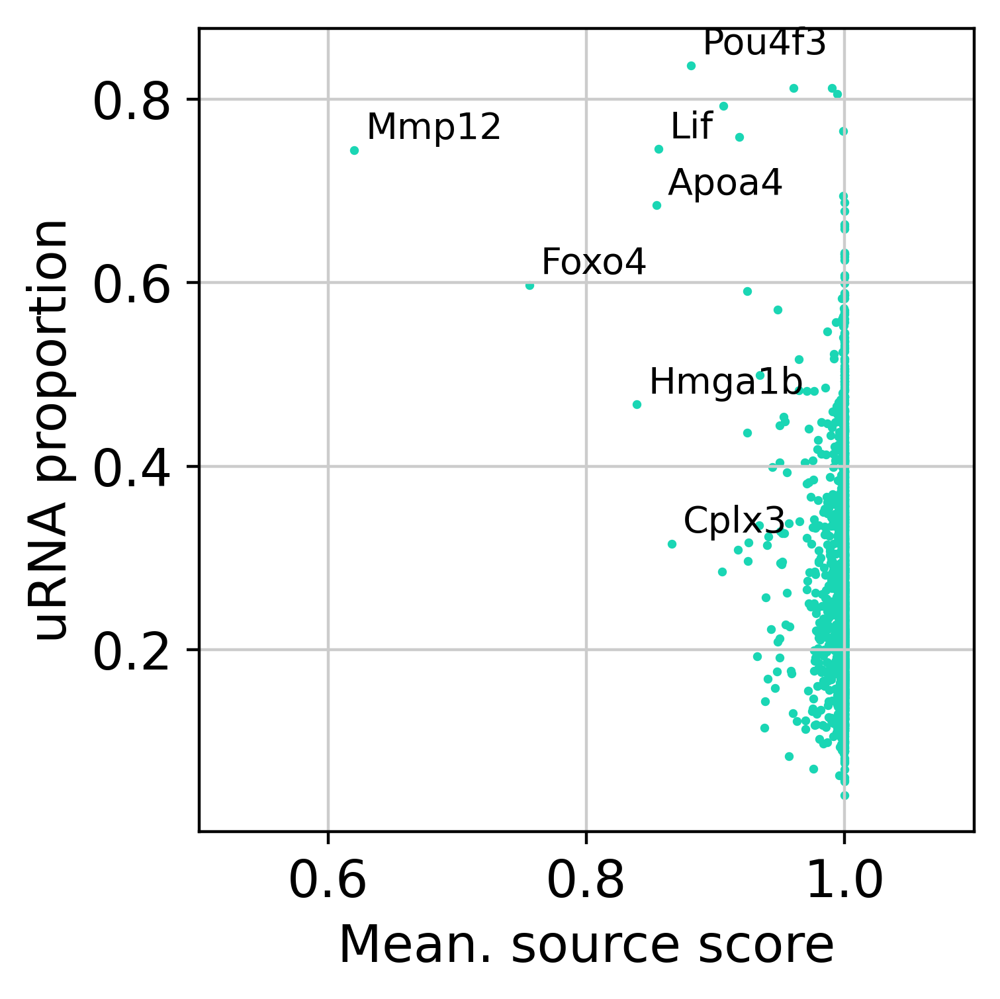

In [194]:
import matplotlib
import matplotlib.pyplot as plt
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
sc.set_figure_params(scanpy=True, dpi=200, dpi_save=200, frameon=True, vector_friendly=True, fontsize=14, figsize=(10,4), color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')

# Thresholds for annotation
x_thresh = 0.9        # e.g. source score must be < 1
y_thresh = 0        # e.g. total counts must be > 1000

# Plot
plt.figure(figsize=(4, 4))
plt.scatter(
    combined_urna_metadata['sum_source_score'],
    combined_urna_metadata['extracellular_proportion'],
    s=2,c='#1ad6b4'
)
plt.xlabel('Mean. source score')
plt.ylabel('uRNA proportion')
#plt.yscale('log')

# Annotate selected genes
for gene, row in combined_urna_metadata.iterrows():
    if row['sum_source_score'] < x_thresh and row['extracellular_proportion'] > y_thresh:
        plt.annotate(
            gene,
            (row['sum_source_score'], row['extracellular_proportion']),
            fontsize=10,
            xytext=(3, 3),
            textcoords='offset points'
        )

plt.xlim([0.5,1.1])
plt.tight_layout()
plt.savefig(os.path.join(saving_path,'scatter_uRNA_proportion_vs_source_score.pdf'))

plt.show()


In [ ]:
glist=['Foxo4','Hmga1b','Cplx3','Mmp12','Lif','Apoa4','Pou4f3','Foxo4']
for g in glist:
    fig=troutpy.pl.spatial_transcripts(sdata,gene_list=[g],scatter_size=40,boundary_linewidth=0.1)
    plt.savefig(os.path.join(saving_path,str(g)+'_spatial_transcripts_msbrain.pdf'))

# Compute communication

In [ ]:
troutpy.tl.compute_target_score(sdata,layer="transcripts",lambda_decay=0.1,copy=False,celltype_key="cell_type",gene_key='gene')

Computing target scores for 6,260,348 transcripts in batches of 100000...


  3%|██▌                                                                              | 2/63 [04:18<2:11:20, 129.18s/it]

In [ ]:
troutpy.tl.communication_strength(sdata)

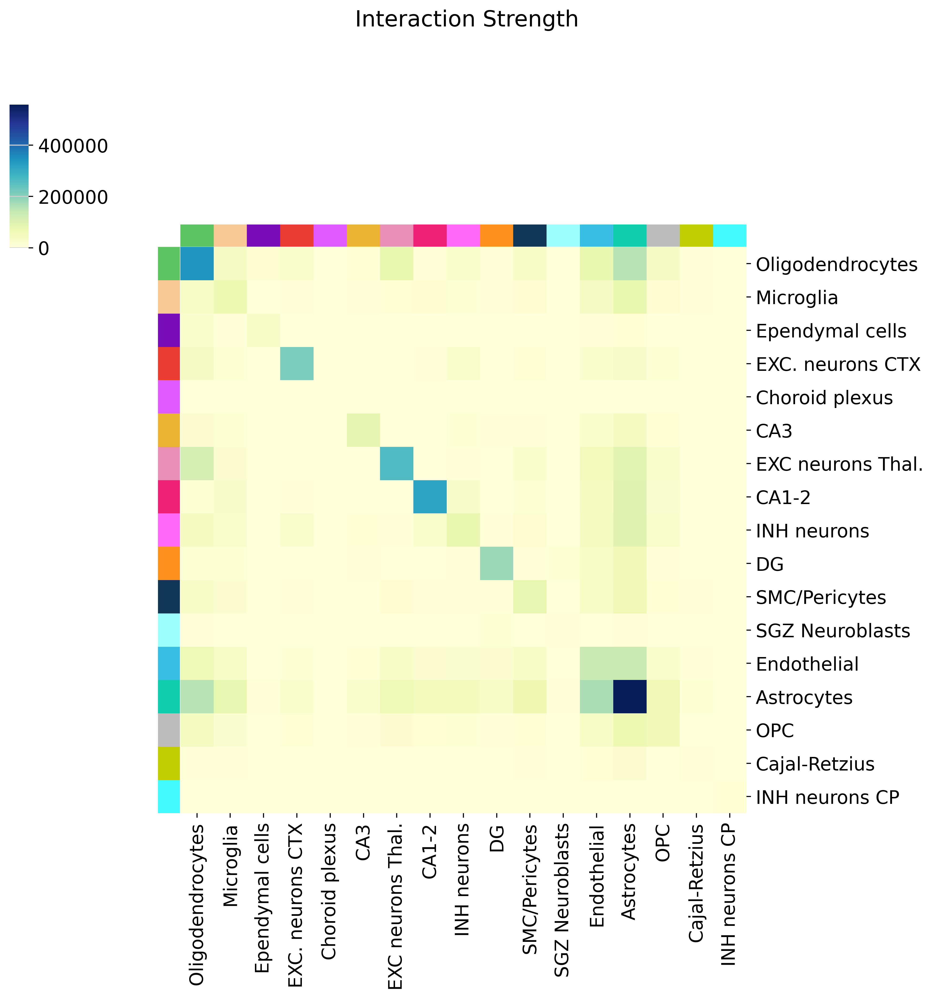

In [317]:
fig=troutpy.pl.celltype_communication(sdata,celltype_key='cell_type',figsize=(10,10),dendrogram_ratio=0.2,cmap='YlGnBu')
plt.savefig(os.path.join(saving_path,'heatmap_n_interaction_strenght.pdf'))

In [318]:
import pandas as pd
import numpy as np
from sklearn.neighbors import BallTree

def count_neighbors_by_cell_type(adata, spatial_key="spatial", cell_type_key="cell_type", distance=50):
    """
    Count the number of neighboring cells for each pair of cell types within a given distance.

    Parameters:
    - adata: AnnData object with cell_type annotation and spatial coordinates
    - spatial_key: key in adata.obs or adata.obsm containing spatial coordinates
    - cell_type_key: key in adata.obs containing cell type annotations
    - distance: radius within which to count neighbors

    Returns:
    - DataFrame (cell_type x cell_type) with counts of neighboring cell-type pairs
    """
    # Get spatial coordinates
    if spatial_key in adata.obsm:
        coords = adata.obsm[spatial_key]
    else:
        coords = adata.obs[spatial_key].tolist()  # if it's a column with arrays

    coords = np.asarray(coords)
    cell_types = adata.obs[cell_type_key].values
    unique_cell_types = np.unique(cell_types)

    # Create a BallTree for fast spatial queries
    tree = BallTree(coords)

    # Query neighbors within distance (excluding self)
    neighbors = tree.query_radius(coords, r=distance)

    # Initialize count matrix
    count_matrix = pd.DataFrame(
        0, index=unique_cell_types, columns=unique_cell_types, dtype=int
    )

    for i, nbr_indices in enumerate(neighbors):
        source_type = cell_types[i]
        for j in nbr_indices:
            if i == j:
                continue  # skip self
            target_type = cell_types[j]
            count_matrix.loc[source_type, target_type] += 1

    return count_matrix


In [319]:
df = count_neighbors_by_cell_type(sdata['table'], spatial_key="spatial", cell_type_key="cell_type", distance=30)

In [320]:
def plot_cell_contact_heatmap(df, sdata, celltype_key="cell type", cmap="Reds", dendrogram_ratio=0.1):
    """
    Plot a heatmap of cell-cell contacts (df), with cell type colors and order matching the interaction plot.

    Parameters
    ----------
    df : pd.DataFrame
        Square DataFrame with cell types on both axes (same as interaction matrix).
    sdata : SpatialData
        SpatialData object containing cell type color and order info.
    celltype_key : str
        Key in `sdata['table'].obs` used for cell type annotation.
    cmap : str
        Color map for the heatmap.
    dendrogram_ratio : float
        Ratio for dendrograms in seaborn clustermap.
    """

    # Match order from interaction strength plot
    source_order = sdata["source_score"].var.index
    target_order = sdata["target_score"].var.index

    df_ordered = df.loc[source_order, target_order]

    # Get colors for cell types
    try:
        cols = dict(zip(
            np.unique(sdata["table"].obs[celltype_key]),
            sdata["table"].uns[celltype_key + "_colors"]
        ))
        colors = [cols[c] for c in source_order]
    except KeyError:
        colpalette = plt.get_cmap("tab20")
        colors = [colpalette(i) for i in range(len(source_order))]

    # Plot
    g = sns.clustermap(
        df_ordered,
        row_cluster=False,
        col_cluster=False,
        row_colors=colors,
        col_colors=colors,
        cmap=cmap,
        dendrogram_ratio=dendrogram_ratio,
        linewidths=0,
        cbar_pos=(0.02, 0.8, 0.02, 0.15),  # left, bottom, width, height
    )

    g.fig.suptitle("Cell-Cell Contacts", y=1.05, fontsize=14)
    plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90)
    plt.setp(g.ax_heatmap.get_yticklabels(), rotation=0)
    g.ax_heatmap.grid(False)



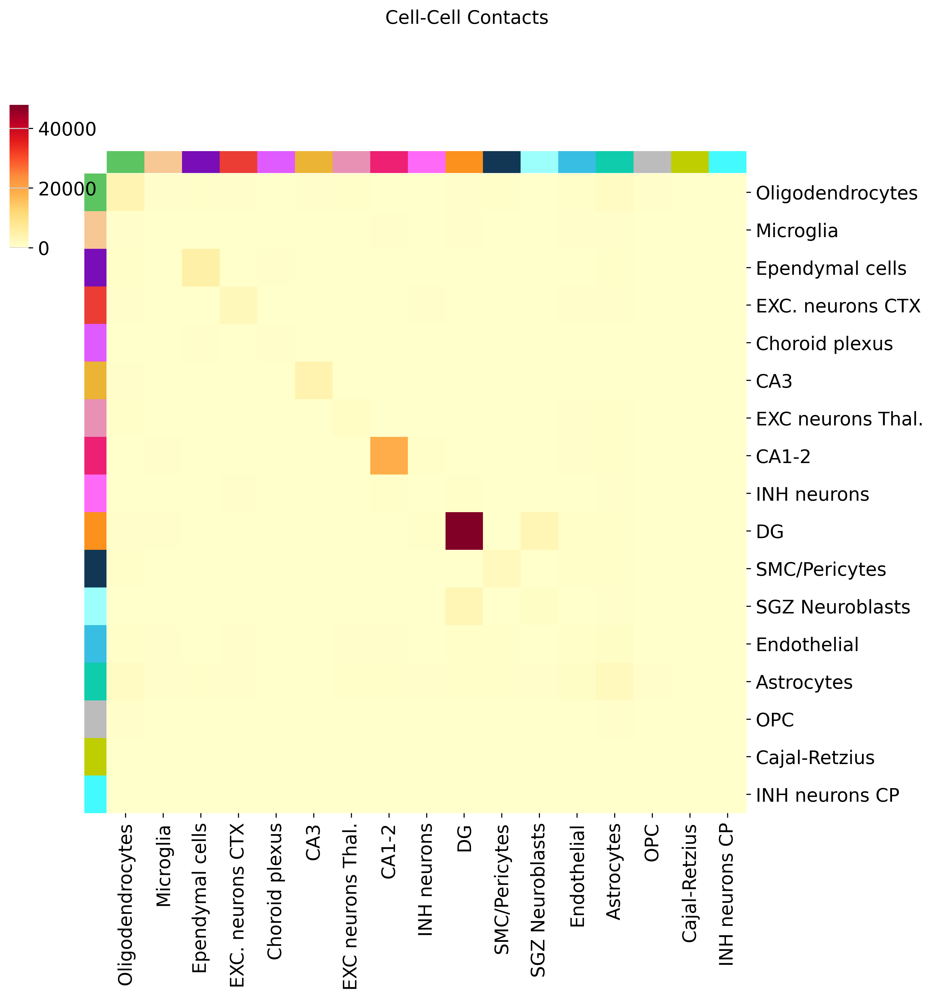

In [321]:
fig=plot_cell_contact_heatmap(df, sdata, celltype_key="cell_type", cmap="YlOrRd", dendrogram_ratio=0.1)
plt.savefig(os.path.join(saving_path,'heatmap_cell_cell_contact.pdf'))

In [323]:
intes=sdata['source_score'].uns['interaction_strength']
source_ct=sdata['source_score'].var.index
target_ct=sdata['target_score'].var.index

annodict=dict(zip(sdata['table'].obs['leiden'],sdata['table'].obs['cell_type']))
celltype_ints=np.sum(intes,axis=0)
celltype_int_table=pd.DataFrame(celltype_ints,index=source_ct,columns=target_ct)

In [324]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import normalize
from scipy.spatial.distance import cosine
from scipy.stats import spearmanr, pearsonr

def compare_interaction_matrices(df1, df2, normalize_rows=True, method='pearson'):
    """
    Compare two interaction matrices after aligning and normalizing.

    Parameters:
    - df1, df2: pandas DataFrames with same cell type labels (may be different order)
    - normalize_rows: whether to row-normalize (relative frequencies)
    - method: 'pearson', 'spearman', or 'cosine' for similarity

    Returns:
    - similarity_score: overall similarity score
    - diff_df: DataFrame of difference (df1_norm - df2_norm)
    """
    # Ensure both dataframes have the same order
    common_index = sorted(set(df1.index).intersection(df2.index))
    df1 = df1.loc[common_index, common_index]
    df2 = df2.loc[common_index, common_index]

    # Normalize
    if normalize_rows:
        df1_norm = df1.div(df1.sum(axis=1), axis=0).fillna(0)
        df2_norm = df2.div(df2.sum(axis=1), axis=0).fillna(0)
    else:
        df1_norm = df1 / df1.values.sum()
        df2_norm = df2 / df2.values.sum()

    # Flatten and compare
    v1 = df1_norm.values.flatten()
    v2 = df2_norm.values.flatten()

    if method == 'pearson':
        score, _ = pearsonr(v1, v2)
    elif method == 'spearman':
        score, _ = spearmanr(v1, v2)
    elif method == 'cosine':
        score = 1 - cosine(v1, v2)
    else:
        raise ValueError("Method must be 'pearson', 'spearman', or 'cosine'.")

    # Difference heatmap
    diff_df = df2_norm-df1_norm

    return score, diff_df


In [325]:
celltype_int_table.shape

(17, 17)

Similarity score: 0.373


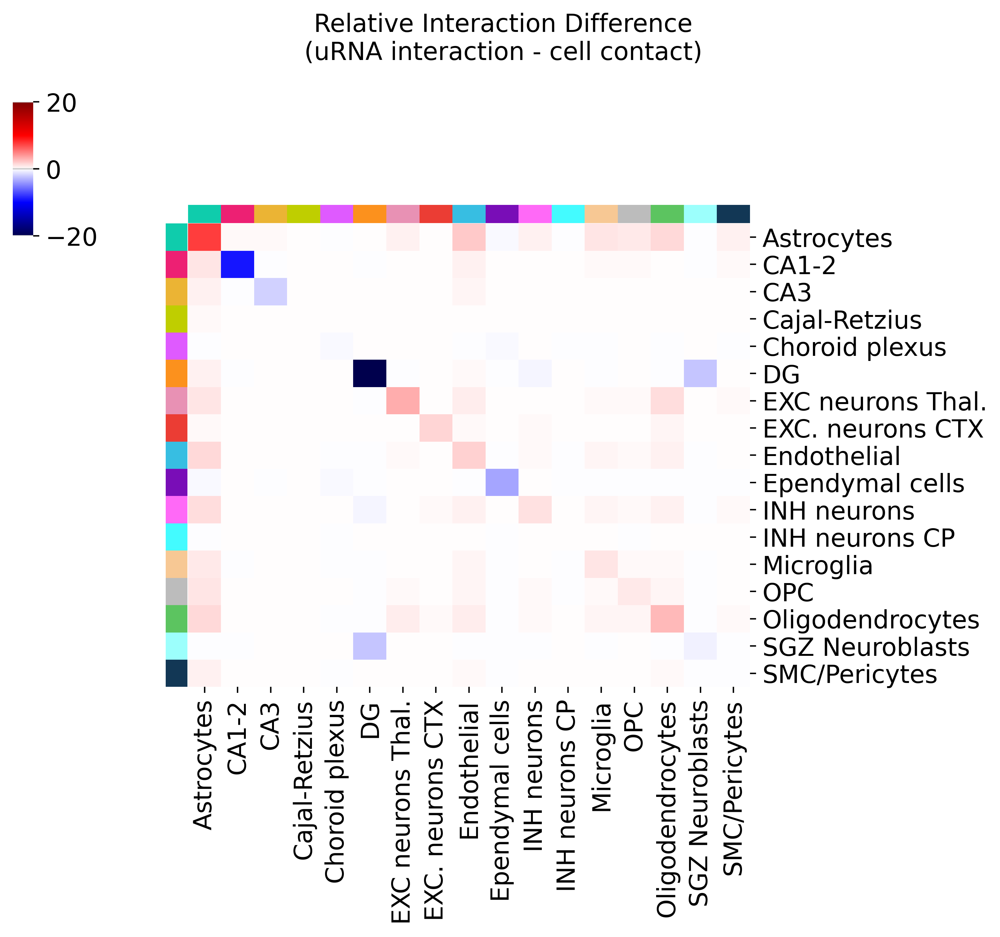

In [330]:
score, diff = compare_interaction_matrices(df, celltype_int_table, normalize_rows=False, method='pearson')
print(f"Similarity score: {score:.3f}")

import seaborn as sns
import matplotlib.pyplot as plt

# Ensure df and celltype_int_table have same order (already assumed done in `compare_interaction_matrices`)
cell_types = diff.index

# Get cell type colors from sdata
cols = dict(zip(
    np.unique(sdata["table"].obs["cell_type"]),
    sdata["table"].uns["cell_type_colors"]
))
row_colors = [cols[ct] for ct in cell_types]
col_colors = [cols[ct] for ct in diff.columns]

# Plot
g = sns.clustermap(
    diff * 100,
    cmap='seismic',
    center=0,
    vmin=-20,
    vmax=20,
    row_colors=row_colors,
    col_colors=col_colors,
    row_cluster=False,
    col_cluster=False,
    figsize=(8, 7),
    cbar_pos=(0.02, 0.8, 0.02, 0.15),  # Adjust if needed
)

g.fig.suptitle("Relative Interaction Difference\n(uRNA interaction - cell contact)", fontsize=14, y=1.05)
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90)
plt.setp(g.ax_heatmap.get_yticklabels(), rotation=0)
g.ax_heatmap.grid(False)

plt.savefig(os.path.join(saving_path,'heatmap_interaction_difference_contact_vs_urna_msbrain.pdf'))
plt.show()


Similarity score: 0.373


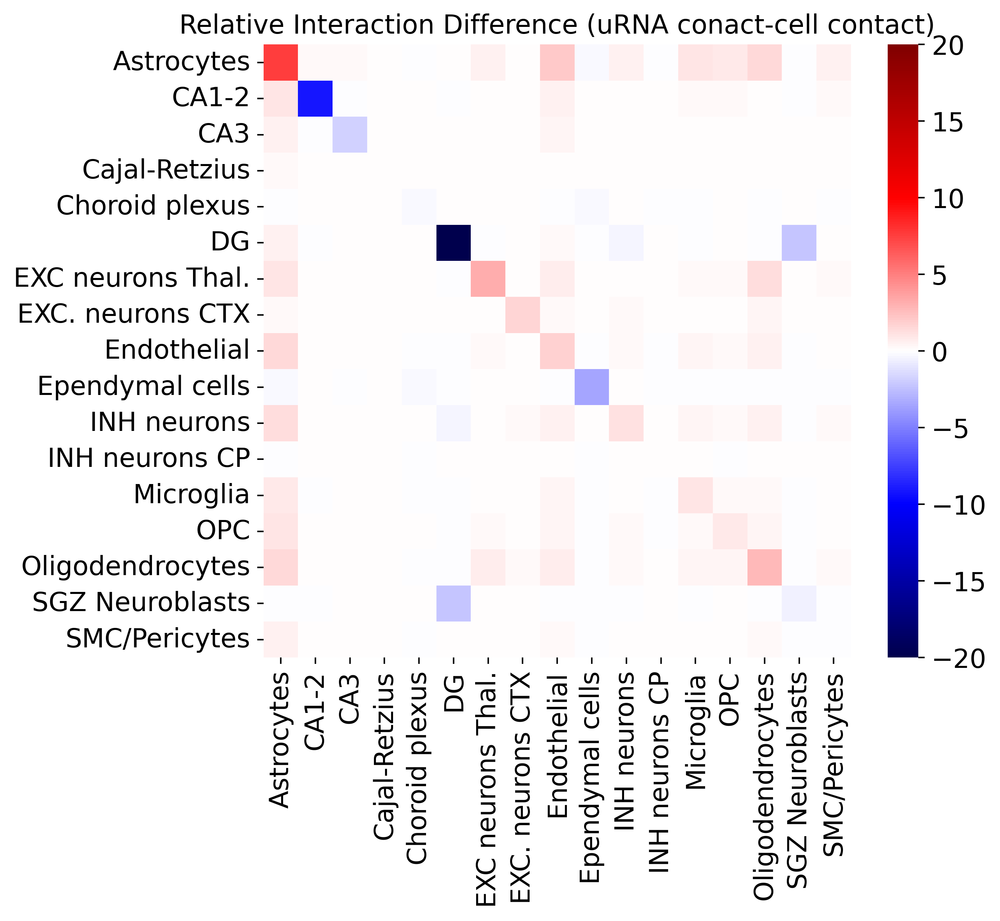

In [327]:

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(7,6))
sns.heatmap(diff*100, cmap='seismic', center=0,vmax=20,vmin=-20)
plt.title("Relative Interaction Difference (uRNA conact-cell contact)")
plt.grid(False)
plt.show()
